<a href="https://colab.research.google.com/github/aidanjohnsonMTech/Final-Project/blob/main/Final_Project_Data_Analysis_with_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import kagglehub
import seaborn as sns
import os

# Create Datasets ai_models and price_hist
path = kagglehub.dataset_download("abirambharathisa/ai-models-and-api-pricing-2026-price-history")
kagglehub.dataset_download('abirambharathisa/ai-models-and-api-pricing-2026-price-history')
price_path = os.path.join(path, "ai_model_price_history.csv")
models_path = os.path.join(path, "ai_models_2026.csv")
price_hist = pd.read_csv(price_path)
ai_models = pd.read_csv(models_path)

Using Colab cache for faster access to the 'ai-models-and-api-pricing-2026-price-history' dataset.
Using Colab cache for faster access to the 'ai-models-and-api-pricing-2026-price-history' dataset.


[Text(0.5, 0, 'Count'),
 Text(0, 0.5, 'Developer'),
 Text(0.5, 1.0, 'Top 20 Most Listed AI Models')]

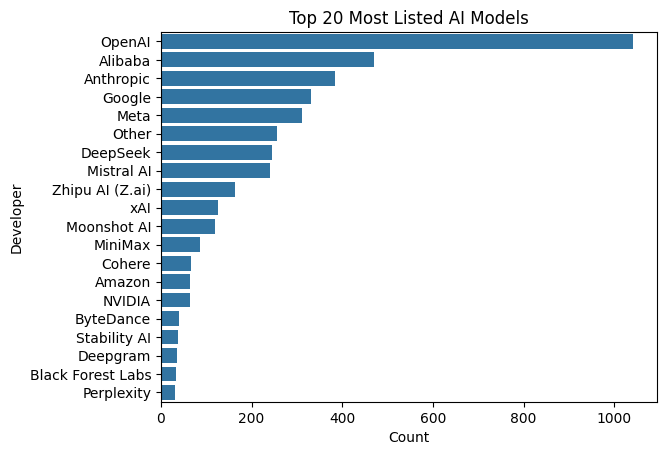

In [84]:
# Group model name and developer
ai_models['dev_uni'] = ai_models['developer'] + ai_models['model_name']
price_hist['dev_uni'] = price_hist['developer'] + price_hist['model_name']

# Developer Plot
dev_plot = sns.countplot(y ='developer', data=ai_models,order=ai_models['developer'].value_counts().iloc[:20].index)
dev_plot.set(xlabel='Count', ylabel='Developer',title='Top 20 Most Listed AI Models')

[Text(0.5, 0, 'Count'),
 Text(0, 0.5, 'Country'),
 Text(0.5, 1.0, 'Number of AI Models per Country')]

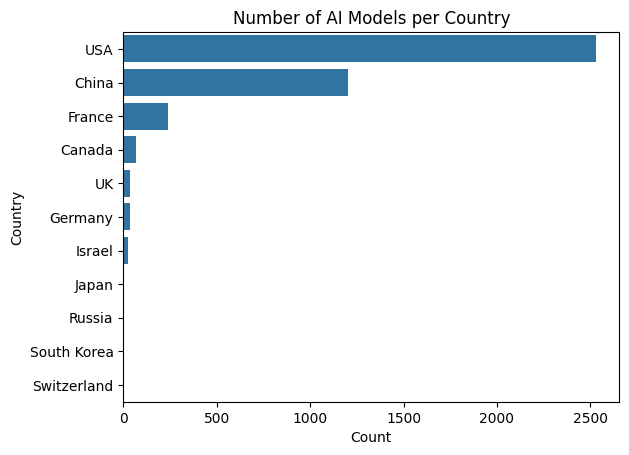

In [85]:
# Country Plot
country_plot = sns.countplot(y ='developer_country', data=ai_models,order=ai_models['developer_country'].value_counts().drop('Unknown', errors='ignore').index)
country_plot.set(xlabel='Count', ylabel='Country',title='Number of AI Models per Country')

[Text(0.5, 0, 'Price per 1 Million Tokens'),
 Text(0, 0.5, 'Country'),
 Text(0.5, 1.0, 'USA vs Chinese')]

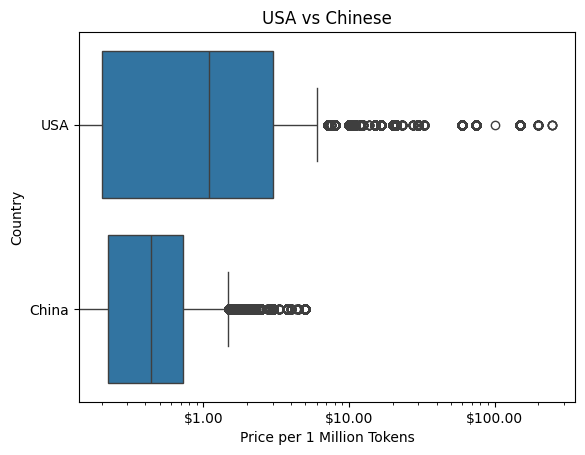

In [86]:
# Top 2 Prices Chart
us_china_df= ai_models[ai_models['developer_country'].isin(['USA', 'China'])]
full_merged = pd.merge(price_hist, ai_models[['model_name', 'developer_country']])
merged_us_china = pd.merge(price_hist, us_china_df[['model_name', 'developer_country']],on='model_name',
    how='inner' )
vs_plot = sns.boxplot(x ='input_price_per_1m_tokens', y='developer_country', data=merged_us_china,order=['USA','China'])
#I used AI to determine how to format the plot better
vs_plot.set_xscale('log')
vs_plot.xaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.2f}'))
#continuing with the plot
vs_plot.set(xlabel='Price per 1 Million Tokens', ylabel='Country', title='USA vs Chinese')

In [89]:
# Calculate average price per million tokens by developer to be able to compare between them
full_merged.groupby('developer')['input_price_per_1m_tokens'].mean()

,input_price_per_1m_tokens
developer,
01.AI,1.545015
AI21 Labs,1.932756
Alibaba,0.426230
Amazon,0.527544
Anthropic,4.992565
Arcee AI,0.147500
BAAI,0.034119
Baidu,0.223906
Black Forest Labs,0.067000
